# 02. Calibração, limiar e explicação do modelo

Usa o modelo salvo em `models/` e o mesmo conjunto de teste do treino (20% dos pacientes, nunca vistos pelo modelo). Rode `scripts/train.py` antes deste notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.artifacts import load_artifacts
from src.data_loading import TARGET_COLUMN, build_cohort, load_raw_data
from src.feature_engineering import CATEGORICAL_FEATURES, NUMERIC_FEATURES, RAW_INPUT_COLUMNS
from src.modeling import split_by_patient

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# Mesmos parâmetros do treino (scripts/train.py), para reproduzir o conjunto de teste.
TEST_SIZE, RANDOM_STATE = 0.2, 42

cohort = build_cohort(load_raw_data(PROJECT_ROOT / "data" / "diabetic_data.csv"))
_, test = split_by_patient(cohort, TEST_SIZE, RANDOM_STATE)
artifacts = load_artifacts(PROJECT_ROOT / "models")
pipeline, threshold = artifacts.pipeline, artifacts.threshold

X_test = test[list(RAW_INPUT_COLUMNS)]
y_test = test[TARGET_COLUMN].to_numpy()
proba = pipeline.predict_proba(X_test)[:, 1]
print(f"modelo: {artifacts.model_name} | limiar: {threshold:.4f}")
print(f"teste: {len(test)} atendimentos | ROC-AUC: {roc_auc_score(y_test, proba):.4f}")

C:\Users\Site5\Health-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


modelo: XGBoost | limiar: 0.1368
teste: 19718 atendimentos | ROC-AUC: 0.6801


## Calibração

Uma probabilidade de 0,20 deveria corresponder a cerca de 20% de readmissões. O gráfico divide o teste em dez faixas de mesmo tamanho e compara o previsto com o observado.

   previsto  observado
0     0.041      0.035
1     0.056      0.048
2     0.066      0.066
3     0.077      0.077
4     0.089      0.091
5     0.103      0.098
6     0.119      0.115
7     0.139      0.140
8     0.171      0.154
9     0.282      0.286

média prevista: 0.1143 | prevalência: 0.1110


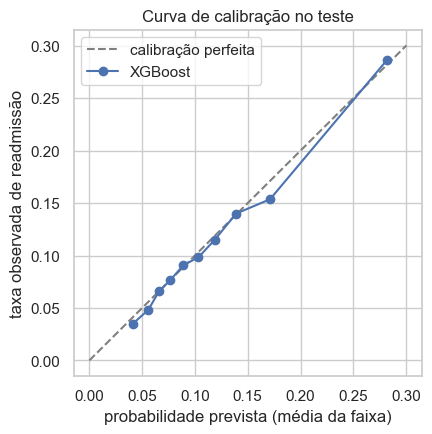

In [2]:
observado, previsto = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
calibracao = pd.DataFrame({"previsto": previsto, "observado": observado})
print(calibracao.to_string())
print(f"\nmédia prevista: {proba.mean():.4f} | prevalência: {y_test.mean():.4f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
limite = max(previsto.max(), observado.max()) * 1.05
ax.plot([0, limite], [0, limite], linestyle="--", color="gray", label="calibração perfeita")
ax.plot(previsto, observado, marker="o", label=artifacts.model_name)
ax.set_xlabel("probabilidade prevista (média da faixa)")
ax.set_ylabel("taxa observada de readmissão")
ax.set_title("Curva de calibração no teste")
ax.legend()
plt.show()

## Limiar de decisão

O limiar salvo maximiza o F1 na validação cruzada. A tabela mostra o que muda ao escolher outro: quantos pacientes são sinalizados, quantos dos sinalizados são readmitidos (precisão) e quantas readmissões são encontradas (recall).

        sinalizados  precisão  recall
limiar                               
0.080         0.621     0.145   0.811
0.100         0.473     0.162   0.692
0.137         0.257     0.204   0.472
0.200         0.094     0.289   0.245
0.300         0.027     0.411   0.101
0.500         0.005     0.571   0.024


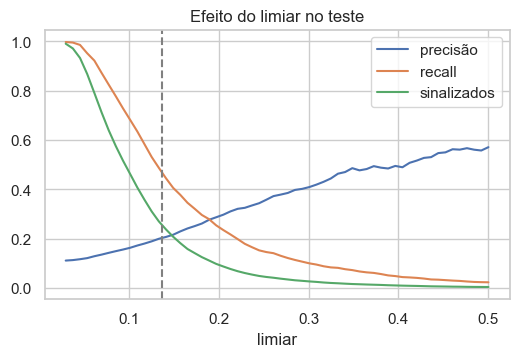

In [3]:
def resumo_limiar(corte):
    alerta = proba >= corte
    return {
        "limiar": corte,
        "sinalizados": alerta.mean(),
        "precisão": y_test[alerta].mean() if alerta.any() else np.nan,
        "recall": alerta[y_test == 1].mean(),
    }


cortes = sorted({0.08, 0.10, round(threshold, 4), 0.20, 0.30, 0.50})
tabela_limiar = pd.DataFrame([resumo_limiar(c) for c in cortes]).set_index("limiar")
print(tabela_limiar.to_string())

grade = np.linspace(0.03, 0.5, 60)
curvas = pd.DataFrame([resumo_limiar(c) for c in grade]).set_index("limiar")
ax = curvas[["precisão", "recall", "sinalizados"]].plot(figsize=(6, 3.5), title="Efeito do limiar no teste")
ax.axvline(threshold, linestyle="--", color="gray")
plt.show()

## SHAP

O SHAP reparte cada previsão entre os atributos. Os valores estão em log-odds: positivo empurra o risco para cima, negativo para baixo. O classificador recebe os atributos já transformados (numéricos padronizados e categorias em colunas 0/1), então o SHAP é calculado nesse espaço.

In [4]:
# A matriz precisa ir esparsa, como no treino: o XGBoost trata o zero implícito de uma
# matriz esparsa como ausente, e a versão densa da mesma matriz percorre outros ramos das árvores.
transformado = pipeline[:-1].transform(X_test)
nomes = pipeline.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(pipeline.named_steps["classifier"])
valores = explainer.shap_values(transformado)
base = float(np.ravel(explainer.expected_value)[0])

# O SHAP é aditivo: base + soma dos valores = log-odds previsto.
logodds = np.log(proba / (1 - proba))
diferenca = np.abs(base + valores.sum(axis=1) - logodds).max()
print(f"maior diferença entre base + soma(SHAP) e o log-odds do modelo: {diferenca:.2e}")
assert diferenca < 1e-3, "SHAP não reproduz a previsão do modelo"

# Para os gráficos, os numéricos aparecem na escala original em vez da padronizada.
atributos = pipeline.named_steps["features"].transform(X_test)
exibicao = transformado.toarray()
exibicao[:, : len(NUMERIC_FEATURES)] = atributos[list(NUMERIC_FEATURES)].to_numpy(dtype=float)
explicacao = shap.Explanation(values=valores, base_values=np.full(len(valores), base), data=exibicao, feature_names=list(nomes))
print(f"{transformado.shape[1]} colunas transformadas, {len(RAW_INPUT_COLUMNS)} colunas de entrada")

maior diferença entre base + soma(SHAP) e o log-odds do modelo: 3.81e-06


148 colunas transformadas, 28 colunas de entrada


### Importância global por atributo

As colunas 0/1 de uma mesma variável categórica são somadas antes de tirar a média do valor absoluto.

number_inpatient           0.231
discharge_disposition_id   0.226
prior_visits               0.103
diag_1_group               0.072
number_diagnoses           0.056
medical_specialty          0.052
num_medications            0.043
age_mid                    0.042
insulin                    0.041
diag_2_group               0.039
diabetesMed                0.036
diag_3_group               0.035
num_lab_procedures         0.035
metformin                  0.034
time_in_hospital           0.031


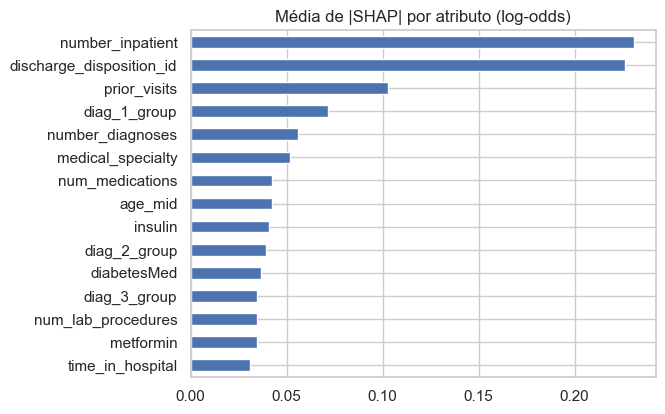


top 10 pela importância por permutação (queda de ROC-AUC), para comparar:


                 feature  importance_mean  importance_std
        number_inpatient            0.074           0.003
discharge_disposition_id            0.050           0.004
                  diag_1            0.007           0.001
       medical_specialty            0.006           0.001
         num_medications            0.005           0.001
        number_emergency            0.004           0.001
        number_diagnoses            0.003           0.001
        time_in_hospital            0.003           0.001
                     age            0.003           0.000
             diabetesMed            0.002           0.000


In [5]:
def atributo_de_origem(nome):
    bloco, resto = nome.split("__", 1)
    if bloco == "num":
        return resto
    candidatos = [c for c in CATEGORICAL_FEATURES if resto == c or resto.startswith(c + "_")]
    return max(candidatos, key=len)


origem = np.array([atributo_de_origem(n) for n in nomes])
shap_por_atributo = pd.DataFrame(valores, columns=nomes).T.groupby(origem).sum().T
importancia = shap_por_atributo.abs().mean().sort_values(ascending=False)
print(importancia.head(15).to_string())

ax = importancia.head(15).iloc[::-1].plot.barh(figsize=(6, 4.5), title="Média de |SHAP| por atributo (log-odds)")
plt.show()

permutacao = pd.read_csv(PROJECT_ROOT / "reports" / "feature_importance.csv")
print("\ntop 10 pela importância por permutação (queda de ROC-AUC), para comparar:")
print(permutacao.head(10).to_string(index=False))

### Direção do efeito

Cada ponto é um atendimento. A cor é o valor do atributo e a posição horizontal é o efeito na previsão. Nas colunas `cat__`, vermelho significa que o atendimento pertence àquela categoria.

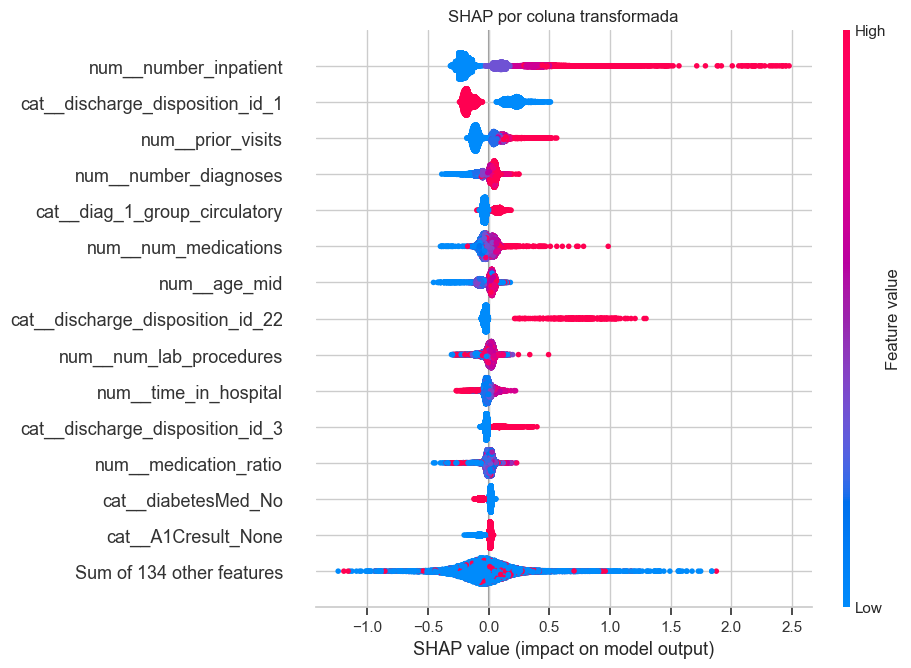

In [6]:
shap.plots.beeswarm(explicacao, max_display=15, show=False)
plt.title("SHAP por coluna transformada")
plt.show()

### Internações anteriores

                   size   mean
number_inpatient              
0                 13248 -0.205
1                  3735  0.092
2                  1368  0.372
3                   628  0.498
4                   333  0.573
5                   165  0.985
6                   241  1.304


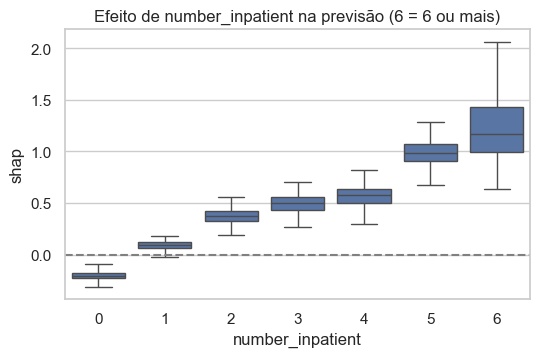

In [7]:
efeito = pd.DataFrame(
    {
        "number_inpatient": X_test["number_inpatient"].clip(upper=6).to_numpy(),
        "shap": shap_por_atributo["number_inpatient"].to_numpy(),
    }
)
print(efeito.groupby("number_inpatient")["shap"].agg(["size", "mean"]).to_string())
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=efeito, x="number_inpatient", y="shap", showfliers=False, ax=ax)
ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Efeito de number_inpatient na previsão (6 = 6 ou mais)")
plt.show()

### Destino da alta

In [8]:
destino = pd.DataFrame(
    {
        "discharge_disposition_id": X_test["discharge_disposition_id"].to_numpy(),
        "shap": shap_por_atributo["discharge_disposition_id"].to_numpy(),
    }
)
resumo_destino = destino.groupby("discharge_disposition_id")["shap"].agg(["size", "mean"])
print(resumo_destino[resumo_destino["size"] >= 100].sort_values("mean", ascending=False).to_string())

                           size   mean
discharge_disposition_id              
22                          378  1.079
5                           248  0.850
2                           440  0.370
3                          2742  0.264
7                           106  0.220
4                           175  0.169
18                          748  0.147
6                          2603  0.042
25                          201 -0.075
1                         11911 -0.211


### Um paciente de alto risco

Explicação individual do atendimento com a maior probabilidade prevista no teste.

probabilidade prevista: 0.848 | readmitido em <30 dias: False
age                         [20-30)
number_inpatient                 12
number_emergency                  5
discharge_disposition_id          1
time_in_hospital                  1
diag_1                       250.12


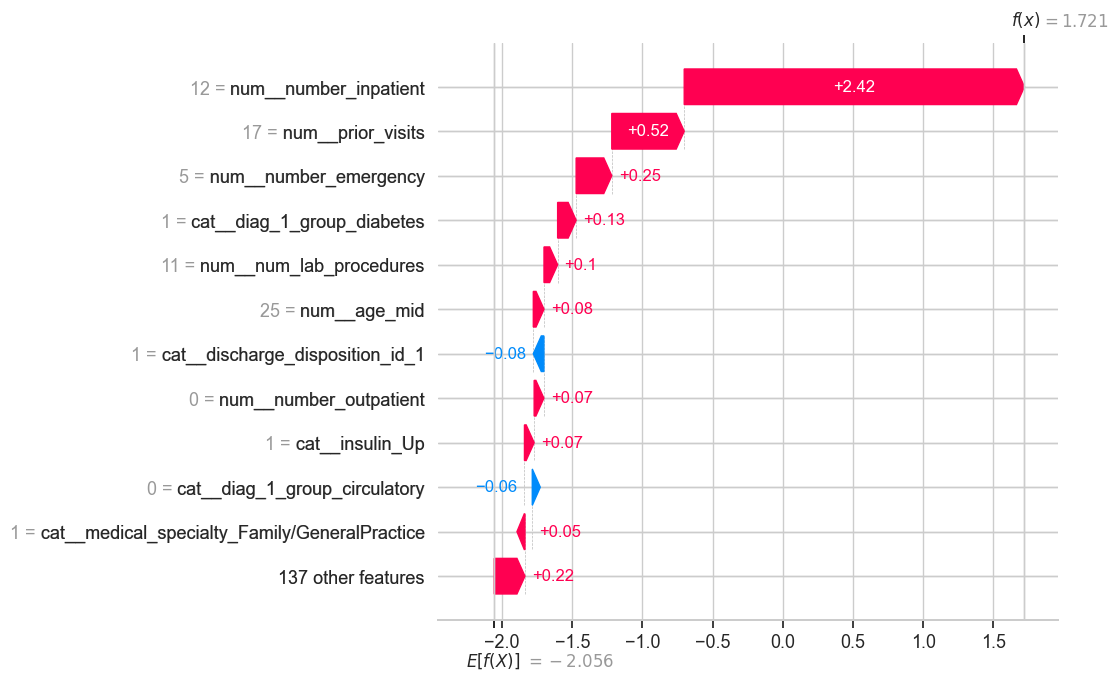

In [9]:
i = int(np.argmax(proba))
print(f"probabilidade prevista: {proba[i]:.3f} | readmitido em <30 dias: {bool(y_test[i])}")
print(X_test.iloc[i][["age", "number_inpatient", "number_emergency", "discharge_disposition_id", "time_in_hospital", "diag_1"]].to_string())
shap.plots.waterfall(explicacao[i], max_display=12, show=False)
plt.show()

## O que o modelo mostra

- **Calibração boa.** Nas dez faixas, o previsto fica a menos de 2 pontos percentuais do observado. O maior desvio está na nona faixa (0,171 previsto, 0,154 observado). Na faixa de maior risco o modelo prevê 0,282 e a taxa real é 0,286. A probabilidade pode ser lida como risco.
- **O limiar é uma escolha de operação.** No limiar salvo (0,137) o modelo sinaliza 25,7% dos atendimentos, acerta 20,4% dos alertas e encontra 47,2% das readmissões. Com 0,10 encontra 69,2%, mas sinaliza 47,3% dos atendimentos. Com 0,20 sinaliza 9,4% e acerta 28,9%, encontrando 24,5%. O melhor valor depende de quantos pacientes a equipe consegue acompanhar.
- **Dois atributos dominam.** `number_inpatient` (0,231) e `discharge_disposition_id` (0,226) têm o dobro da média de |SHAP| do terceiro, `prior_visits` (0,103), que é derivado do mesmo histórico. A importância por permutação aponta os mesmos dois primeiros.
- **Direção coerente com a exploração.** Nenhuma internação anterior reduz o log-odds em 0,21 em média, e seis ou mais aumentam em 1,30. Alta para reabilitação (código 22) soma 1,08 e alta para casa (código 1) subtrai 0,21.
- **Explicação individual não é veredito.** O atendimento de maior risco previsto (0,848) tinha 12 internações no ano anterior e não foi readmitido em 30 dias.

**Limites.** O SHAP explica o que o modelo faz, não o que causa readmissão. O ROC-AUC de 0,68 é modesto: o modelo ordena risco melhor que o acaso, mas erra muito em casos individuais. Os dados são de hospitais dos EUA entre 1999 e 2008.

**Detalhe técnico.** O cálculo do SHAP só reproduz a previsão quando a matriz é passada esparsa, como no treino. A célula do SHAP verifica isso com um `assert`.